In [1]:
# STEP 1: Install required libraries

!pip install -q pycocotools opencv-python matplotlib seaborn pandas pillow tqdm

print("All libraries installed successfully!")

All libraries installed successfully!


In [4]:
from google.colab import files

uploaded = files.upload()

print("Files uploaded successfully!")

for filename in uploaded:
    print(filename)

Saving traffic_annotations.json to traffic_annotations (1).json
Files uploaded successfully!
traffic_annotations (1).json


In [7]:
from google.colab import files

uploaded = files.upload()

print("Uploaded successfully!")

Saving traffic_annotations.json to traffic_annotations (2).json
Uploaded successfully!


In [12]:
import json
import pandas as pd
import os

# Automatically find uploaded JSON file
json_file = [f for f in os.listdir('/content') if f.endswith('.json')][0]

print("Using file:", json_file)

# Load COCO JSON
with open('/content/' + json_file, 'r') as f:
    coco = json.load(f)

images = coco["images"]
categories = coco["categories"]
annotations = coco["annotations"]

print("\n========== DATASET INFORMATION ==========")
print("Total Images:", len(images))
print("Total Categories:", len(categories))
print("Total Annotations:", len(annotations))

print("\n========== IMAGE DETAILS ==========")
for img in images:
    print("Image:", img["file_name"])
    print("Width:", img["width"])
    print("Height:", img["height"])

print("\n========== CATEGORIES ==========")
for cat in categories:
    print(cat["id"], "-", cat["name"])

Using file: traffic_annotations (1).json

========== DATASET INFORMATION ==========
Total Images: 1
Total Categories: 5
Total Annotations: 27

========== IMAGE DETAILS ==========
Image: traffic.jpg
Width: 612
Height: 408

========== CATEGORIES ==========
1 - car
2 - bus
3 - truck
4 - motorcycle
5 - auto_rickshaw


CLASS DISTRIBUTION


,Class,Count
0,bus,1
1,truck,1
2,auto_rickshaw,3
3,motorcycle,3
4,car,19


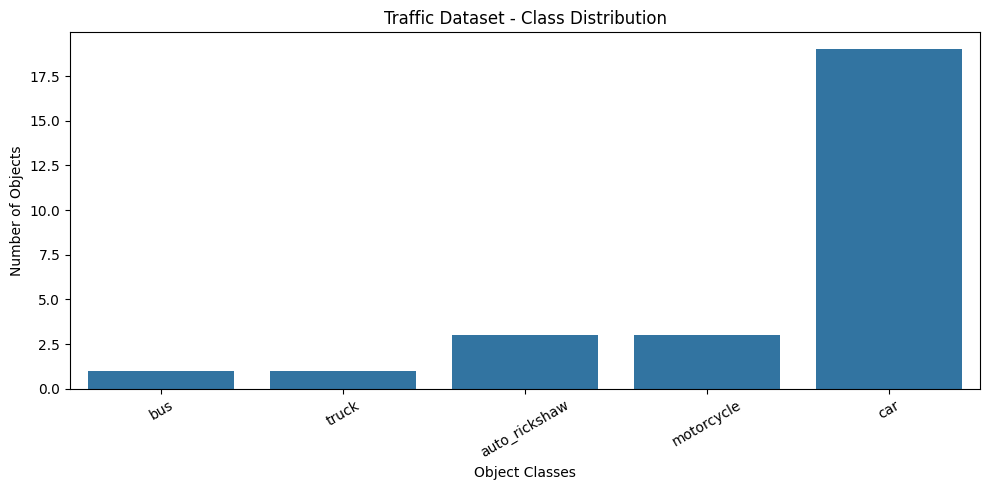

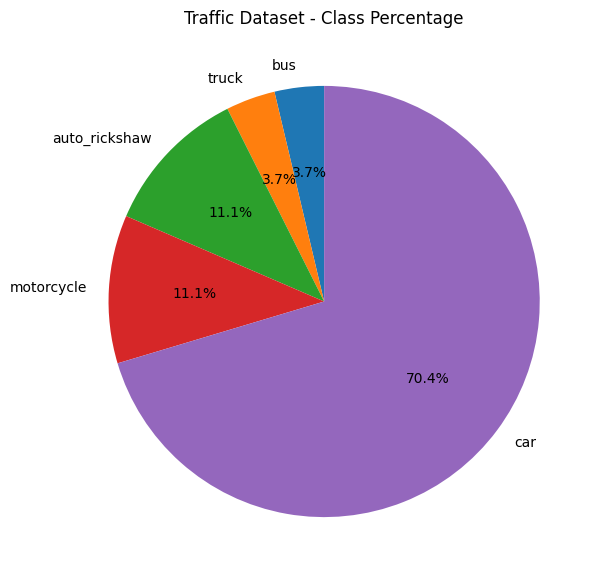

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Get category names
category_names = {
    cat["id"]: cat["name"]
    for cat in categories
}

# Count objects in each class
class_counts = {}

for ann in annotations:
    name = category_names[ann["category_id"]]
    class_counts[name] = class_counts.get(name, 0) + 1

# Display counts
df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Count"]
)

print("CLASS DISTRIBUTION")
display(df)

# Bar Chart
plt.figure(figsize=(10, 5))
sns.barplot(data=df, x="Class", y="Count")

plt.title("Traffic Dataset - Class Distribution")
plt.xlabel("Object Classes")
plt.ylabel("Number of Objects")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Pie Chart
plt.figure(figsize=(7, 7))
plt.pie(
    df["Count"],
    labels=df["Class"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Traffic Dataset - Class Percentage")
plt.show()

In [14]:
from google.colab import files

uploaded_images = files.upload()

print("Image uploaded successfully!")

Saving traffic.jpg to traffic.jpg
Image uploaded successfully!


In [15]:
import cv2
import os
import matplotlib.pyplot as plt
import pandas as pd

image_files = [
    f for f in uploaded_images
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
]

quality_results = []

for filename in image_files:

    img = cv2.imread(filename)

    if img is None:
        print(filename, "- Corrupted or unreadable")
        continue

    height, width = img.shape[:2]

    # Calculate image sharpness
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    sharpness = cv2.Laplacian(gray, cv2.CV_64F).var()

    quality = "Blurry" if sharpness < 100 else "Good"

    quality_results.append({
        "Image": filename,
        "Width": width,
        "Height": height,
        "Resolution": f"{width}x{height}",
        "Sharpness": round(sharpness, 2),
        "Quality": quality
    })

df_quality = pd.DataFrame(quality_results)

display(df_quality)

,Image,Width,Height,Resolution,Sharpness,Quality
0,traffic.jpg,612,408,612x408,2828.66,Good


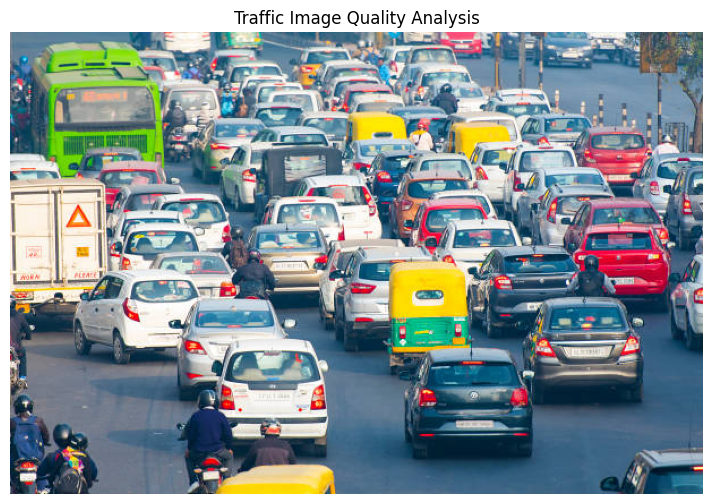

In [16]:
for filename in image_files:

    img = cv2.imread(filename)

    if img is not None:
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(10, 6))
        plt.imshow(img_rgb)
        plt.title("Traffic Image Quality Analysis")
        plt.axis("off")
        plt.show()

In [17]:
import pandas as pd

# Create lookup dictionaries
image_info = {
    img["id"]: img for img in coco["images"]
}

category_ids = {
    cat["id"] for cat in coco["categories"]
}

valid_annotations = []
invalid_annotations = []

for ann in coco["annotations"]:

    errors = []

    # Check image ID
    img = image_info.get(ann["image_id"])

    if img is None:
        errors.append("Missing image ID")
    else:
        width = img["width"]
        height = img["height"]

        x, y, w, h = ann["bbox"]

        # Check bounding box dimensions
        if w <= 0 or h <= 0:
            errors.append("Invalid width or height")

        # Check image boundaries
        if x < 0 or y < 0 or x + w > width or y + h > height:
            errors.append("Bounding box outside image")

    # Check category ID
    if ann["category_id"] not in category_ids:
        errors.append("Invalid category ID")

    # Check area
    x, y, w, h = ann["bbox"]

    if ann["area"] != w * h:
        errors.append("Incorrect annotation area")

    if errors:
        invalid_annotations.append({
            "Annotation ID": ann["id"],
            "Errors": ", ".join(errors)
        })
    else:
        valid_annotations.append(ann["id"])

print("========== ANNOTATION VALIDATION ==========")
print("Total Annotations:", len(annotations))
print("Valid Annotations:", len(valid_annotations))
print("Invalid Annotations:", len(invalid_annotations))

if invalid_annotations:
    display(pd.DataFrame(invalid_annotations))
else:
    print("All annotations passed validation!")

========== ANNOTATION VALIDATION ==========
Total Annotations: 27
Valid Annotations: 27
Invalid Annotations: 0
All annotations passed validation!


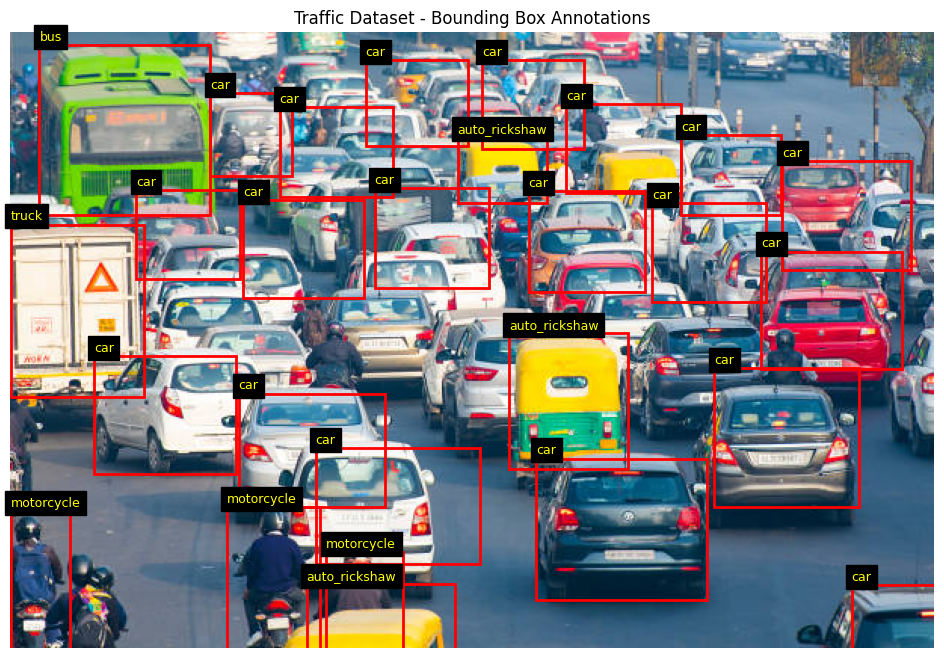

In [18]:
import cv2
import matplotlib.pyplot as plt

image_path = "/content/traffic.jpg"

image = cv2.imread(image_path)

if image is None:
    print("Please upload traffic.jpg first!")
else:
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(14, 8))
    plt.imshow(image)

    for ann in annotations:

        x, y, w, h = ann["bbox"]

        category_name = category_names[ann["category_id"]]

        rectangle = plt.Rectangle(
            (x, y), w, h,
            fill=False,
            edgecolor="red",
            linewidth=2
        )

        plt.gca().add_patch(rectangle)

        plt.text(
            x, y - 3,
            category_name,
            color="yellow",
            fontsize=9,
            backgroundcolor="black"
        )

    plt.title("Traffic Dataset - Bounding Box Annotations")
    plt.axis("off")
    plt.show()

========== FINAL DATASET AUDIT REPORT ==========


,Metric,Result
0,Total Images,1
1,Total Classes,5
2,Total Annotations,27
3,Valid Annotations,27
4,Invalid Annotations,0



========== CLASS DISTRIBUTION ==========


,Class,Count
0,bus,1
1,truck,1
2,auto_rickshaw,3
3,motorcycle,3
4,car,19


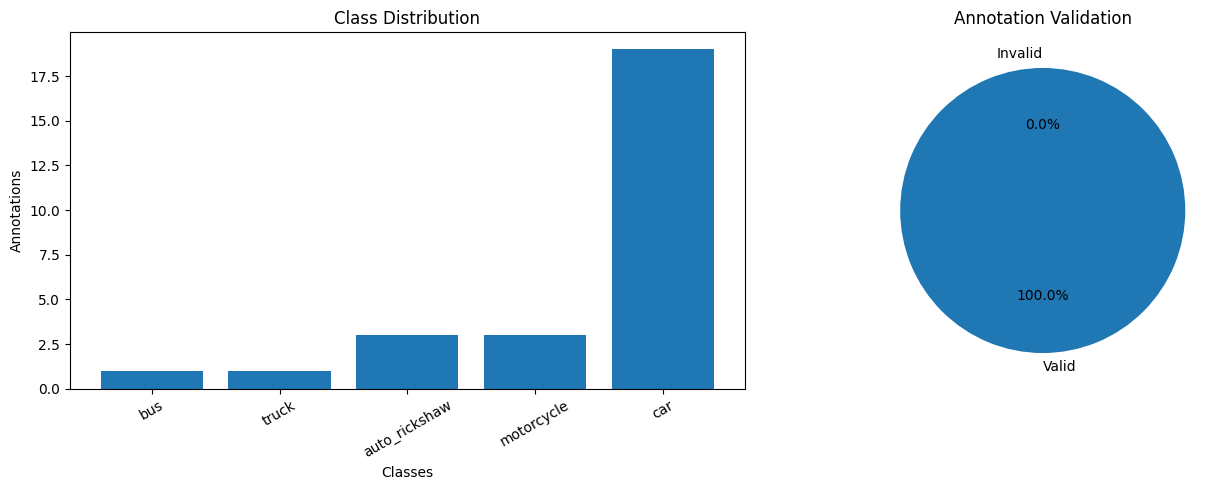

Final audit report saved successfully!


In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import json
import os

# Dataset summary
total_images = len(coco["images"])
total_classes = len(coco["categories"])
total_annotations = len(coco["annotations"])

# Class distribution
class_counts = {}

for ann in coco["annotations"]:
    name = category_names[ann["category_id"]]
    class_counts[name] = class_counts.get(name, 0) + 1

# Annotation validation summary
valid_count = len(valid_annotations)
invalid_count = len(invalid_annotations)

# Create final report
report = {
    "Metric": [
        "Total Images",
        "Total Classes",
        "Total Annotations",
        "Valid Annotations",
        "Invalid Annotations"
    ],
    "Result": [
        total_images,
        total_classes,
        total_annotations,
        valid_count,
        invalid_count
    ]
}

report_df = pd.DataFrame(report)

print("========== FINAL DATASET AUDIT REPORT ==========")
display(report_df)

print("\n========== CLASS DISTRIBUTION ==========")
display(pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Count"]
))

# Final visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(class_counts.keys(), class_counts.values())
axes[0].set_title("Class Distribution")
axes[0].set_xlabel("Classes")
axes[0].set_ylabel("Annotations")
axes[0].tick_params(axis="x", rotation=30)

axes[1].pie(
    [valid_count, invalid_count],
    labels=["Valid", "Invalid"],
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("Annotation Validation")

plt.tight_layout()
plt.show()

# Save report
report_df.to_csv("dataset_audit_report.csv", index=False)

print("Final audit report saved successfully!")

In [20]:
from google.colab import files

files.download("dataset_audit_report.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
import json
import pandas as pd
from datetime import datetime

# Generate summary
summary = {
    "Experiment": "Dataset Audit and Visualisation",
    "Dataset": "Indian Traffic Images",
    "Total Images": len(coco["images"]),
    "Total Classes": len(coco["categories"]),
    "Total Annotations": len(coco["annotations"]),
    "Valid Annotations": len(valid_annotations),
    "Invalid Annotations": len(invalid_annotations),
    "Class Distribution": class_counts,
    "Image Dimensions": "612 x 408",
    "Date": datetime.now().strftime("%d-%m-%Y")
}

# Save JSON report
with open("final_audit_summary.json", "w") as f:
    json.dump(summary, f, indent=4)

print("========== FINAL AUDIT SUMMARY ==========")

for key, value in summary.items():
    print(f"{key}: {value}")

print("\nAudit summary generated successfully!")

========== FINAL AUDIT SUMMARY ==========
Experiment: Dataset Audit and Visualisation
Dataset: Indian Traffic Images
Total Images: 1
Total Classes: 5
Total Annotations: 27
Valid Annotations: 27
Invalid Annotations: 0
Class Distribution: {'bus': 1, 'truck': 1, 'auto_rickshaw': 3, 'motorcycle': 3, 'car': 19}
Image Dimensions: 612 x 408
Date: 23-11-2026

Audit summary generated successfully!


In [22]:
from google.colab import files
files.download("final_audit_summary.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
from google.colab import files

print("Upload your traffic.jpg image")
uploaded_image = files.upload()

Upload your traffic.jpg image


Saving traffic_annotations.json to traffic_annotations (3).json


Image loaded successfully!
Image dimensions: 612 x 408


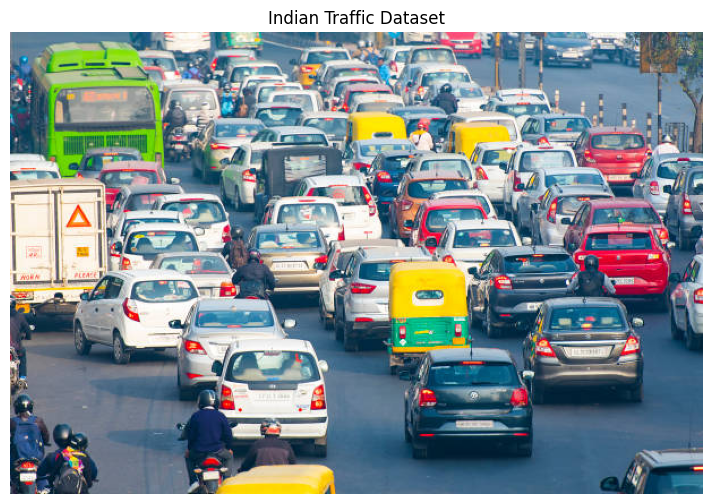

In [24]:
import cv2
import matplotlib.pyplot as plt

image = cv2.imread("traffic.jpg")

if image is not None:
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    print("Image loaded successfully!")
    print("Image dimensions:", image.shape[1], "x", image.shape[0])

    plt.figure(figsize=(12, 6))
    plt.imshow(image)
    plt.title("Indian Traffic Dataset")
    plt.axis("off")
    plt.show()
else:
    print("Image not found. Check the uploaded filename.")

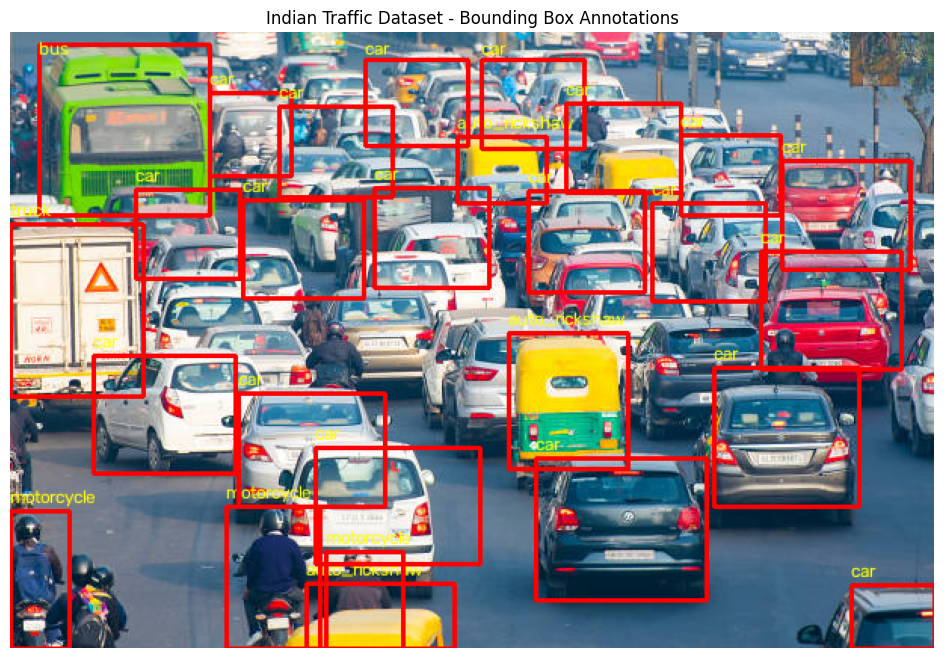

In [25]:
import cv2
import matplotlib.pyplot as plt

# Load traffic image
image = cv2.imread("traffic.jpg")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Draw bounding boxes
for ann in annotations:

    x, y, w, h = ann["bbox"]

    class_name = category_names[ann["category_id"]]

    # Draw rectangle
    cv2.rectangle(
        image,
        (int(x), int(y)),
        (int(x+w), int(y+h)),
        (255, 0, 0),
        2
    )

    # Add class label
    cv2.putText(
        image,
        class_name,
        (int(x), max(15, int(y)-5)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.4,
        (255, 255, 0),
        1
    )

# Display result
plt.figure(figsize=(14, 8))
plt.imshow(image)
plt.title("Indian Traffic Dataset - Bounding Box Annotations")
plt.axis("off")
plt.show()

In [26]:
from PIL import Image

annotated_image = Image.fromarray(image)

annotated_image.save("annotated_traffic.jpg")

from google.colab import files
files.download("annotated_traffic.jpg")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
import cv2
import pandas as pd
import matplotlib.pyplot as plt

# Load original image
img = cv2.imread("traffic.jpg")

# Image quality analysis
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

height, width = img.shape[:2]
sharpness = cv2.Laplacian(gray, cv2.CV_64F).var()

# Dataset statistics
print("========== FINAL DATASET STATISTICS ==========")

print("Image Resolution:", width, "x", height)
print("Total Classes:", len(categories))
print("Total Objects:", len(annotations))
print("Valid Bounding Boxes:", len(valid_annotations))
print("Invalid Bounding Boxes:", len(invalid_annotations))
print("Image Sharpness:", round(sharpness, 2))

if sharpness < 100:
    print("Image Quality: Potentially Blurry")
else:
    print("Image Quality: Good")

# Display statistics
statistics = {
    "Metric": [
        "Image Width",
        "Image Height",
        "Total Classes",
        "Total Objects",
        "Valid Annotations",
        "Invalid Annotations",
        "Sharpness"
    ],
    "Value": [
        width,
        height,
        len(categories),
        len(annotations),
        len(valid_annotations),
        len(invalid_annotations),
        round(sharpness, 2)
    ]
}

display(pd.DataFrame(statistics))

========== FINAL DATASET STATISTICS ==========
Image Resolution: 612 x 408
Total Classes: 5
Total Objects: 27
Valid Bounding Boxes: 27
Invalid Bounding Boxes: 0
Image Sharpness: 2828.66
Image Quality: Good


,Metric,Value
0,Image Width,612.00
1,Image Height,408.00
2,Total Classes,5.00
3,Total Objects,27.00
4,Valid Annotations,27.00
5,Invalid Annotations,0.00
6,Sharpness,2828.66


In [28]:
import os
import shutil

os.makedirs("Dataset_Audit_Results", exist_ok=True)

# Save original image
shutil.copy("traffic.jpg", "Dataset_Audit_Results/traffic.jpg")

# Save annotated image if available
if os.path.exists("annotated_traffic.jpg"):
    shutil.copy(
        "annotated_traffic.jpg",
        "Dataset_Audit_Results/annotated_traffic.jpg"
    )

# Save annotation validation
pd.DataFrame({
    "Valid Annotation IDs": valid_annotations
}).to_csv(
    "Dataset_Audit_Results/valid_annotations.csv",
    index=False
)

# Save class distribution
df.to_csv(
    "Dataset_Audit_Results/class_distribution.csv",
    index=False
)

# Save quality report
df_quality.to_csv(
    "Dataset_Audit_Results/image_quality.csv",
    index=False
)

# Download everything as ZIP
shutil.make_archive(
    "Dataset_Audit_Results",
    "zip",
    "Dataset_Audit_Results"
)

from google.colab import files
files.download("Dataset_Audit_Results.zip")

print("All practical results saved!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All practical results saved!
